# Operasi Dasar Citra Digital: Gaussian Blur dan Median Filter

**Nama:** Andre Wijaya  
**NIM:** 24260024

## Tujuan
Membandingkan dua metode penyaringan citra. Gaussian Blur menghaluskan gambar menggunakan bobot Gaussian, sedangkan Median Filter mengganti nilai piksel dengan median tetangganya. Untuk menguji pengaruh filter, notebook membuat simulasi *salt-and-pepper noise* pada salinan grayscale. **Foto asli tidak diubah.**

## 1. Membaca citra dan memeriksa data
Sel ini membaca foto sumber, menampilkan dimensi, jumlah piksel, tipe data, rentang intensitas, dan gambar asli.

Nama file      : foto.jpg
Ukuran         : 1200 × 1599 piksel
Jumlah piksel  : 1918800
Bentuk RGB     : (1599, 1200, 3)
Tipe data      : uint8
Rentang gray   : 0 sampai 255


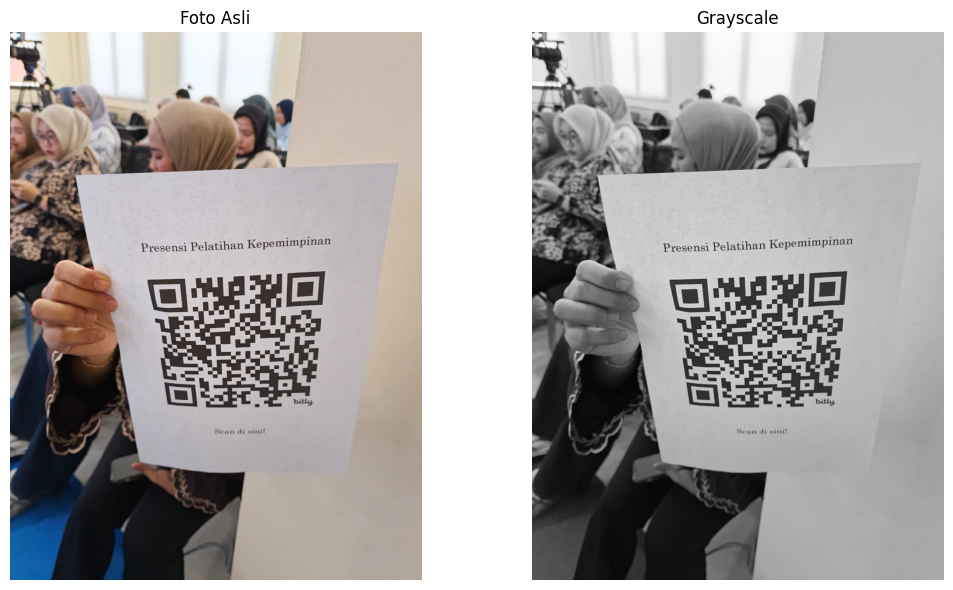

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PATH_FOTO = Path("foto.jpg")
if not PATH_FOTO.exists():
    raise FileNotFoundError("File foto.jpg tidak ditemukan. Letakkan foto.jpg di folder yang sama dengan notebook.")

gambar_bgr = cv2.imread(str(PATH_FOTO))
if gambar_bgr is None:
    raise ValueError("Gambar tidak dapat dibaca. Periksa file foto.jpg.")

gambar_rgb = cv2.cvtColor(gambar_bgr, cv2.COLOR_BGR2RGB)
gambar_gray = cv2.cvtColor(gambar_bgr, cv2.COLOR_BGR2GRAY)
tinggi, lebar = gambar_gray.shape

print("Nama file      :", PATH_FOTO.name)
print("Ukuran         :", f"{lebar} × {tinggi} piksel")
print("Jumlah piksel  :", lebar * tinggi)
print("Bentuk RGB     :", gambar_rgb.shape)
print("Tipe data      :", gambar_rgb.dtype)
print("Rentang gray   :", int(gambar_gray.min()), "sampai", int(gambar_gray.max()))

fig, ax = plt.subplots(1, 2, figsize=(11, 6))
ax[0].imshow(gambar_rgb); ax[0].set_title("Foto Asli"); ax[0].axis("off")
ax[1].imshow(gambar_gray, cmap="gray"); ax[1].set_title("Grayscale"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 2. Membuat salt-and-pepper noise

Noise berupa bintik hitam dan putih ditambahkan secara buatan pada salinan grayscale. Langkah ini memungkinkan kita membandingkan kemampuan filter dalam mengurangi gangguan yang sama.

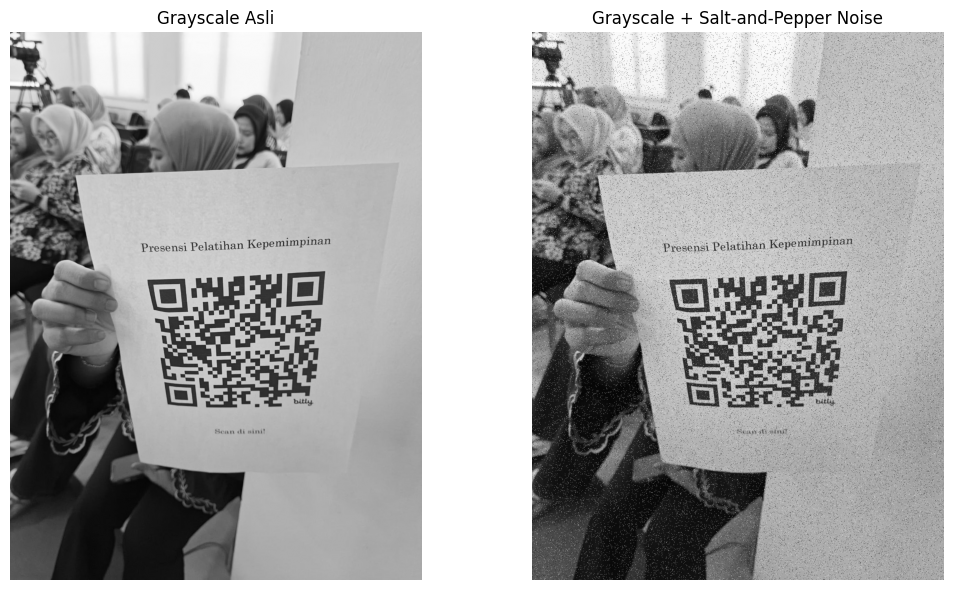

Tingkat noise yang diminta: 5.0%


In [2]:
TINGKAT_NOISE = 0.05
SEED_ACAK = 42

def tambah_salt_pepper(citra, tingkat=0.05, seed=42):
    hasil = citra.copy()
    rng = np.random.default_rng(seed)
    acak = rng.random(citra.shape)
    hasil[acak < tingkat / 2] = 0
    hasil[(acak >= tingkat / 2) & (acak < tingkat)] = 255
    return hasil

gray_noise = tambah_salt_pepper(gambar_gray, TINGKAT_NOISE, SEED_ACAK)

fig, ax = plt.subplots(1, 2, figsize=(11, 6))
ax[0].imshow(gambar_gray, cmap="gray"); ax[0].set_title("Grayscale Asli"); ax[0].axis("off")
ax[1].imshow(gray_noise, cmap="gray"); ax[1].set_title("Grayscale + Salt-and-Pepper Noise"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print(f"Tingkat noise yang diminta: {TINGKAT_NOISE * 100:.1f}%")

## 3. Gaussian Blur dan Median Filter

Kedua filter menggunakan kernel 5×5. Gaussian Blur menghitung rata-rata berbobot, sedangkan Median Filter mengambil nilai tengah dari lingkungan piksel. Median Filter sering efektif untuk noise salt-and-pepper.

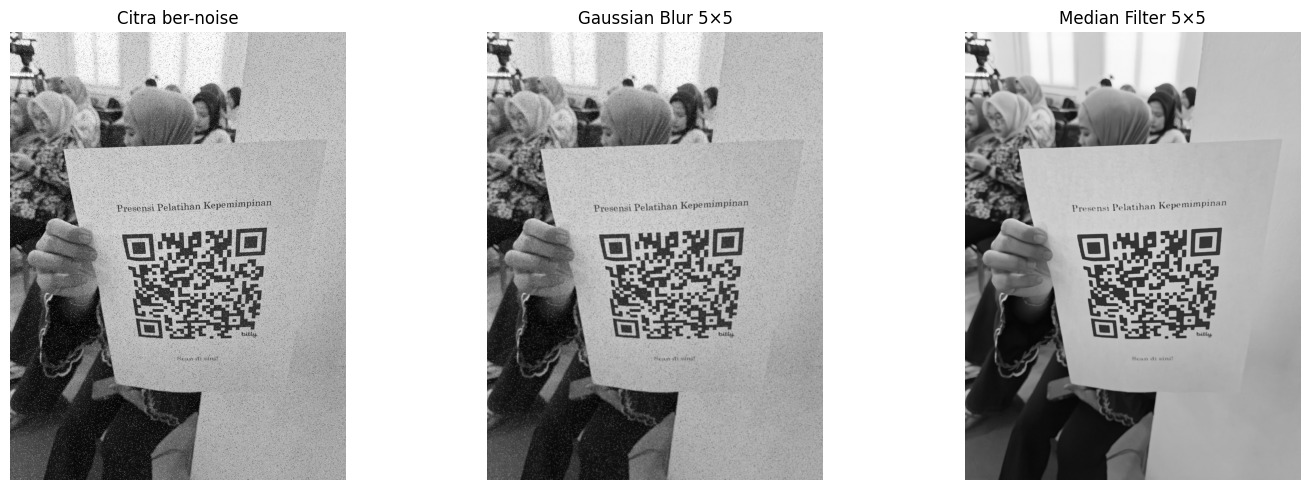

In [3]:
UKURAN_KERNEL = 5
hasil_gaussian = cv2.GaussianBlur(gray_noise, (UKURAN_KERNEL, UKURAN_KERNEL), 0)
hasil_median = cv2.medianBlur(gray_noise, UKURAN_KERNEL)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for sumbu, judul, data in [
    (ax[0], "Citra ber-noise", gray_noise),
    (ax[1], "Gaussian Blur 5×5", hasil_gaussian),
    (ax[2], "Median Filter 5×5", hasil_median),
]:
    sumbu.imshow(data, cmap="gray", vmin=0, vmax=255)
    sumbu.set_title(judul)
    sumbu.axis("off")
plt.tight_layout(); plt.show()

## 4. Evaluasi dengan MSE dan PSNR

MSE menghitung rata-rata kuadrat selisih piksel terhadap citra grayscale asli. PSNR dinyatakan dalam dB. Nilai ini membantu perbandingan numerik, tetapi tidak selalu mewakili semua aspek kualitas visual.

In [4]:
def hitung_mse(referensi, uji):
    selisih = referensi.astype(np.float64) - uji.astype(np.float64)
    return float(np.mean(selisih ** 2))

def hitung_psnr(referensi, uji):
    mse = hitung_mse(referensi, uji)
    if mse == 0:
        return float("inf")
    return float(10 * np.log10((255.0 ** 2) / mse))

data_evaluasi = []
for nama, hasil in [
    ("Citra ber-noise", gray_noise),
    ("Gaussian Blur 5×5", hasil_gaussian),
    ("Median Filter 5×5", hasil_median),
]:
    data_evaluasi.append({
        "Metode": nama,
        "MSE terhadap citra asli": round(hitung_mse(gambar_gray, hasil), 2),
        "PSNR (dB)": round(hitung_psnr(gambar_gray, hasil), 2)
    })

tabel_evaluasi = pd.DataFrame(data_evaluasi)
display(tabel_evaluasi)

,Metode,MSE terhadap citra asli,PSNR (dB)
0,Citra ber-noise,1054.7,17.90
1,Gaussian Blur 5×5,115.9,27.49
2,Median Filter 5×5,21.1,34.89


## 5. Pengaruh ukuran kernel
Uji kernel 3×3, 5×5, dan 7×7 untuk melihat perubahan hasil penghalusan.

,Metode,Kernel,MSE,PSNR (dB)
0,Gaussian Blur,3×3,171.44,25.79
1,Median Filter,3×3,8.44,38.87
2,Gaussian Blur,5×5,115.90,27.49
3,Median Filter,5×5,21.10,34.89
4,Gaussian Blur,7×7,100.76,28.10
5,Median Filter,7×7,44.12,31.68


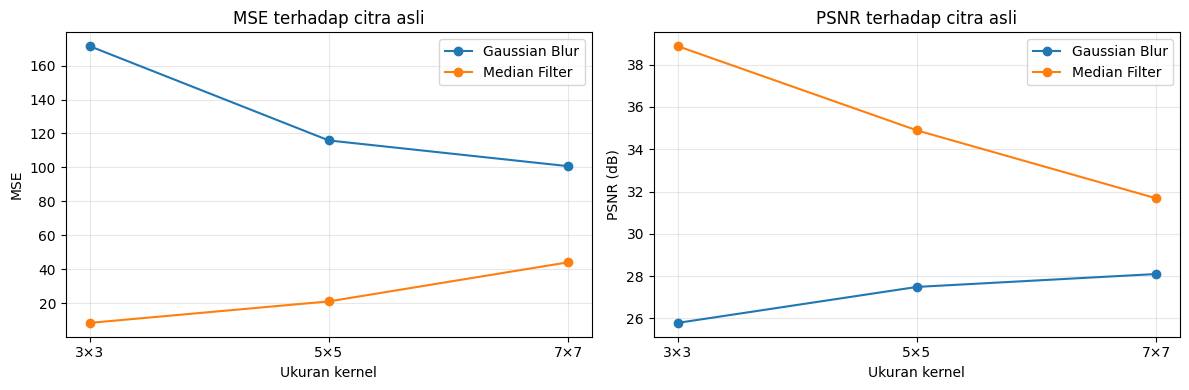

In [5]:
baris = []
for k in [3, 5, 7]:
    gaussian = cv2.GaussianBlur(gray_noise, (k, k), 0)
    median = cv2.medianBlur(gray_noise, k)
    for nama, hasil in [("Gaussian Blur", gaussian), ("Median Filter", median)]:
        baris.append({
            "Metode": nama, "Kernel": f"{k}×{k}",
            "MSE": round(hitung_mse(gambar_gray, hasil), 2),
            "PSNR (dB)": round(hitung_psnr(gambar_gray, hasil), 2)
        })
tabel_kernel = pd.DataFrame(baris)
display(tabel_kernel)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for metode in tabel_kernel["Metode"].unique():
    subset = tabel_kernel[tabel_kernel["Metode"] == metode]
    ax[0].plot(subset["Kernel"], subset["MSE"], marker="o", label=metode)
    ax[1].plot(subset["Kernel"], subset["PSNR (dB)"], marker="o", label=metode)
ax[0].set_title("MSE terhadap citra asli"); ax[0].set_xlabel("Ukuran kernel"); ax[0].set_ylabel("MSE")
ax[1].set_title("PSNR terhadap citra asli"); ax[1].set_xlabel("Ukuran kernel"); ax[1].set_ylabel("PSNR (dB)")
for a in ax:
    a.grid(True, alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

## 6. Menyimpan hasil
Hasil ditulis sebagai file baru di folder `hasil/`. Citra sumber tidak ditimpa.

In [6]:
folder_hasil = Path("hasil")
folder_hasil.mkdir(exist_ok=True)
cv2.imwrite(str(folder_hasil / "salt_pepper_noise.png"), gray_noise)
cv2.imwrite(str(folder_hasil / "gaussian_blur.png"), hasil_gaussian)
cv2.imwrite(str(folder_hasil / "median_filter.png"), hasil_median)
print("Hasil disimpan di:", folder_hasil.resolve())
print(" - salt_pepper_noise.png")
print(" - gaussian_blur.png")
print(" - median_filter.png")

Hasil disimpan di: /mnt/data/Proyek_Operasi_Dasar_Citra_Digital/hasil
 - salt_pepper_noise.png
 - gaussian_blur.png
 - median_filter.png


## 7. Kesimpulan

Gaussian Blur dan Median Filter memiliki cara kerja berbeda. Gaussian Blur menghaluskan perubahan intensitas dengan pembobotan Gaussian, sedangkan Median Filter menggunakan nilai tengah tetangga piksel. Hasil visual dan tabel MSE/PSNR dapat digunakan untuk membandingkan keduanya pada foto ini. Metode yang lebih sesuai bergantung pada jenis gangguan dan detail yang ingin dipertahankan.